In [1]:
import sys

from matplotlib import pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import numpy as np
import pandas as pd
import os
import ast
import configparser
from configparser import ConfigParser

In [29]:
BASEPATH = '/Users/janik/source/urban-mobility-simulation'
DATAPATH = os.path.join(BASEPATH, 'data/output')
CONFIGPATH = os.path.join(BASEPATH, 'resources/configurations/app-local.ini')

parser = ConfigParser()
parser.read(CONFIGPATH)

# Configuration
episodes = int(parser.get("DQN", "EPISODES"))
timelimit = parser.getfloat("DYNAMIC_CHECKPOINT_ROUTING", "TIMELIMIT") # multiplier, not the real timelimit
actions = parser.get("DYNAMIC_CHECKPOINT_ROUTING", "ACTION_SPACE").split(',')
action_dim = len(actions)
action_resolution = parser.getint("DYNAMIC_CHECKPOINT_ROUTING", "ACTION_SPACE_RESOLUTION")
eps = parser.getfloat("DQN", "EPS")
eps_decay_strategy = parser.get("DQN", "EPS_DECAY_STRATEGY")
eps_decay = parser.getfloat("DQN", "EPS_DECAY")
eps_max = parser.getfloat("DQN", "EPS_MAX")
eps_min = parser.getfloat("DQN", "EPS_MIN")
buffersize = parser.getint("DQN", "BUFFERSIZE")
min_experience = parser.getint("DQN", "MIN_EXPERIENCE")
target_update_threshold = parser.getint("DQN", "TARGET_UPDATE_THRESHOLD")
try:
    tau = parser.getfloat("DQN", "TAU")
except configparser.NoOptionError:
    tau = None
gamma = parser.getfloat("DQN", "GAMMA")
penalty_unreachable = parser.getint("DYNAMIC_CHECKPOINT_ROUTING", "PENALTY_UNREACHABLE")
penalty_checkpoints = parser.getfloat("DYNAMIC_CHECKPOINT_ROUTING", "PENALTY_CHECKPOINTS")
reward = parser.getint("DYNAMIC_CHECKPOINT_ROUTING", "REWARD")
q_net_layers = ast.literal_eval(parser.get("DQN", "DQN_LAYERS"))
batchsize = parser.getint("DQN", "BATCHSIZE")
lr_decay = parser.getboolean("DQN", "LR_DECAY")
lr_decay_steps = parser.getint("DQN", "LR_DECAY_STEPS")
velocity = parser.getfloat("BUS", "VELOCITY")

## Single Run Evaluation (Debug)

In [30]:
RESULTS = 'data/output/returns/20221012-122631.csv'
RESULTS_PATH = os.path.join(BASEPATH, RESULTS)

results = pd.read_csv(RESULTS_PATH, index_col='episode')

ROLLING = 10

config = {'episodes': episodes,
          'actions': actions,
          'tau': tau,
          'update every n steps': target_update_threshold,
          'penalty_unreachable': penalty_unreachable,
          'penalty_checkpoints': penalty_checkpoints,
          'reward': reward,
          'batchsize': batchsize,
          'q net': q_net_layers
         }

results['return_MA'] = results['return'].rolling(ROLLING).mean()
results['service_level_MA'] = results['service_level'].rolling(ROLLING).mean()
results['reached_destination_MA'] = results['reached_destination'].rolling(ROLLING).mean()



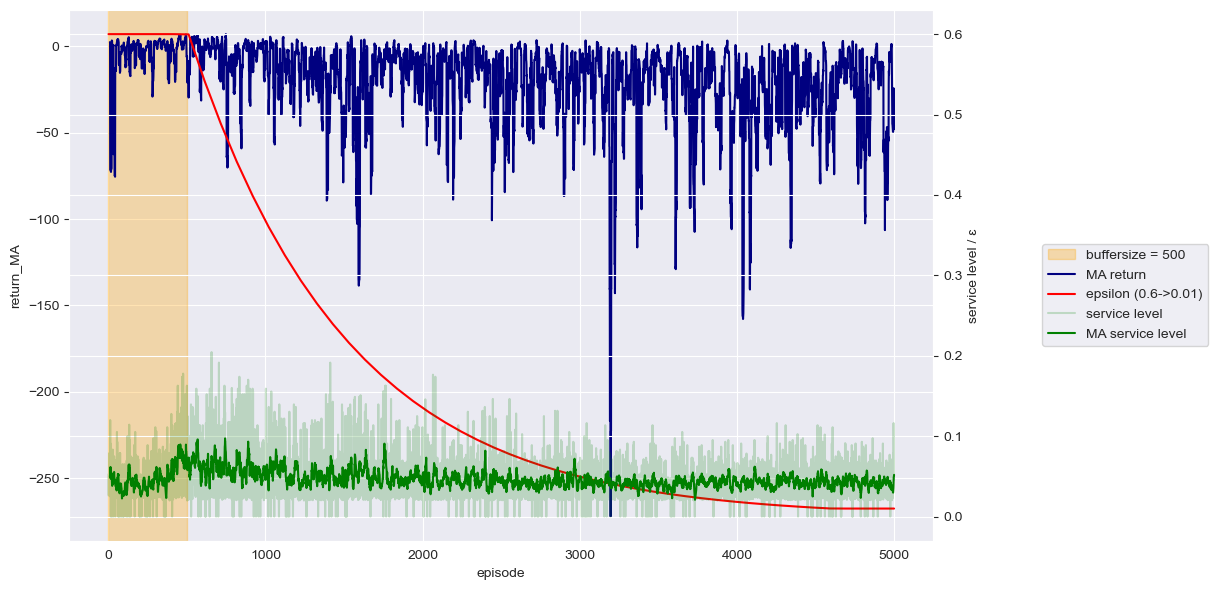

In [31]:
# plot
fig, ax = plt.subplots(figsize=(10,6))
# annotations
plt.axvspan(0, buffersize, color='orange', alpha=.3, label=f'buffersize = {buffersize}')
# plt.axvline(min_experience, color='black', label=f'training start after {episodes} episodes')
x_ = np.linspace(1,episodes)
ax_ = plt.twinx(ax)
ax2 = ax.twinx()
if eps_decay_strategy == 'exp':
    sns.lineplot(x=x_, y=np.maximum(np.minimum(eps_decay**x_, eps_max), eps_min), color='red', ax=ax2, label=f'epsilon ({eps_max}->{eps_min})', legend=False)
if eps_decay_strategy == 'linear':
    sns.lineplot(x=x_, y=np.maximum(np.minimum(1-(1/episodes)*x_, eps_max), eps_min), color='red', ax=ax2, label=f'epsilon: max({eps_min}, 1-(1/episodes)*episode)', legend=False)
ax_.set_axis_off() # hide this axis

# sns.lineplot(data=results, x='episode', y='return', alpha=.2, color='darkblue', label='return', ax=ax, legend=False)
sns.lineplot(data=results, x='episode', y='return_MA', alpha=1, color='navy', label='MA return', ax=ax, legend=False)
sns.lineplot(data=results, x='episode', y='service_level', alpha=.2, color='green', label='service level', ax=ax2, legend=False)
sns.lineplot(data=results, x='episode', y='service_level_MA', alpha=1, color='green', label='MA service level', ax=ax2, legend=False)

# plt.title('Experiment with tanh activation function in hidden layers')
ax2.set_ylabel('service level / ɛ')

handles, labels = [(a + b) for a, b in zip(ax.get_legend_handles_labels(), ax2.get_legend_handles_labels())]
fig.patch.set_facecolor('white')
fig.tight_layout()
# fig.suptitle('Experiment with Penalty = 15, soft update with tau=0.001 at every step', fontsize=15)
# fig.subplots_adjust(top=0.95)
lgd = fig.legend(handles, labels, bbox_to_anchor=(1.04,0.5), loc="center left")
config_handles = []
for k,v in config.items():
    config_handles.append(mpatches.Patch(color='none', label=f'{k} = {v}'))
# lgd2 = fig.legend(handles=config_handles, bbox_to_anchor=(1.04,0.8), loc="center left", title="Configuration")

plt.show()

# Experiment with different agent configurations

In [26]:
plt.rcParams.update({
    'axes.titlesize': 'xx-large',
    'axes.labelsize': 'x-large',
    'legend.fontsize': 'x-large',
    'legend.title_fontsize': 'large'
})

RESULTS = 'search_eps_decay_eps_decay_strategy_seed_experiments_20220116-000611.csv'
COLS = ['episode', 'return', 'service_level', 'lr', 'reached_destination', 'distance', 'duration']

config = {'episodes': episodes, 
          'actions': actions,
          'tau': tau,
          'update every n steps': target_update_threshold,
          'penalty': penalty,
          'reward': reward,
          'learning rate decay': lr_decay,
          'learning rate decay steps': lr_decay_steps,
          'batchsize': batchsize,
          'q net': q_net_layers
         }

results = pd.read_csv(os.path.join(DATAPATH, 'returns', RESULTS))
results.drop(columns='seed', inplace=True, errors='ignore')
experiments = list(set(results) - set(COLS))

for e in experiments:
    config.pop(e, None) # remove this from configuration legend

n_experiments = len(experiments)
if n_experiments > 2:
    raise NotImplementedError('more than two simultaneous experiments are currently not supported')
elif n_experiments == 2 and not 'eps_decay_strategy' in experiments:
    e1 = results[experiments[0]]
    e2 = results[experiments[1]]
    n_e1 = e1.nunique()
    n_e2 = e2.nunique()
    fig, ax = plt.subplots(n_e1, n_e2, figsize=(6*n_e1,4*n_e2))
    ii = 0
    
    for i, (name, group) in enumerate(results.groupby(experiments)):
        group = group.join(group.groupby('episode')['reached_destination'].mean().rolling(100).mean(), on='episode', rsuffix='_MA')
        group['return_MA'] = group['return'].rolling(20).mean()
        group['service_level_MA'] = group['service_level'].rolling(20).mean()
        
        if i >= n_e1:
            ii = i // n_e1
            i -= ii * n_e1

        # annotations
        if 'buffersize' in experiments:
            buffersize_i = experiments.index('buffersize')
            ax[ii][i].axvspan(0, name[buffersize_i], color='orange', alpha=.3, label='buffersize')
        else:
            ax[ii][i].axvspan(0, buffersize, color='orange', alpha=.3, label='buffersize')
        # ax[ii][i].axvline(min_experience, color='black', label='training start')

        x_ = np.linspace(1,episodes)
        ax_ = ax[ii][i].twinx()
        ax2 = ax[ii][i].twinx()
        if 'eps_decay_strategy' in experiments:
            epsdecaystrategy_i = experiments.index('eps_decay_strategy')
            eps_decay_strategy = name[epsdecaystrategy_i]
        if eps_decay_strategy == 'exp':
            if 'eps_decay' in experiments:
                epsdecay_i = experiments.index('eps_decay')
                sns.lineplot(x=x_, y=np.maximum(name[epsdecay_i]**x_, eps_min), color='red', ax=ax2, label=f'ɛ: max({eps_min}, {name}^episode)', legend=False)
            else:
                sns.lineplot(x=x_, y=np.maximum(eps_decay**x_, eps_min), color='red', ax=ax2, label=f'ɛ: max({eps_min}, {eps_decay}^episode)', legend=False)
        if eps_decay_strategy == 'linear':
            sns.lineplot(x=x_, y=np.maximum(1-(1/episodes)*x_, eps_min), color='red', ax=ax2, label=f'ɛ: max({eps_min}, 1-(1/episodes)*episode)', legend=False)
        if eps_decay_strategy == 'none':
            config.pop('eps_decay', None)
            config.pop('eps_min', None)
            config['eps'] = eps
        # hide this axis
        ax_.set_axis_off()

        sns.lineplot(data=group, x='episode', y='return', color='navy', label='return', ax=ax[ii][i], legend=False)
    #         sns.lineplot(data=group, x='episode', y='return_MA', alpha=1, color='blue', label='MA return', ax=ax[i], legend=False)
        sns.lineplot(data=group, x='episode', y='service_level', color='green', label='service level', ax=ax2, legend=False)
    #         sns.lineplot(data=group, x='episode', y='service_level_MA', alpha=1, color='green', label='MA service level', ax=ax2, legend=False)
        sns.lineplot(data=group[group.duplicated(subset=['episode'])], x='episode', y='reached_destination_MA', color='orange', label='% of runs that reach terminal', ax=ax2, legend=False)
        
        ax2.set_ylabel('service level / ɛ')
        
        exp = {k: v for k, v in zip(experiments, name)}
        ax[ii][i].set_title(', '.join(f'{k}: {v}' for k, v in exp.items()))
        
        if i < n_e1-1:
            # left columns
            ax2.set_yticks([])
            ax2.set_ylabel(None)
        if i > 0:
            # right columns
            ax[ii][i].set_yticks([])
            ax[ii][i].set_ylabel(None)
        if ii < n_e1-1:
            # upper rows
            ax[ii][i].set_xticks([])
            ax[ii][i].set_xlabel(None)
    
    handles, labels = [(a + b) for a, b in zip(ax[ii][i].get_legend_handles_labels(), ax2.get_legend_handles_labels())]
    lgd = fig.legend(handles, labels, loc="lower center", ncol=len(labels)//2, bbox_to_anchor=(0.5,-0.125))
    
elif n_experiments == 1 or 'eps_decay_strategy' in experiments:
    if 'eps_decay_strategy' in experiments:
        # display on one axis, linear strategy does not have different decay rates
        i = experiments.index('eps_decay')
        n = results[experiments[i]].nunique()
        experiments_g = [experiments[i]]
    else:
        n = results[experiments[0]].nunique()
        experiments_g = experiments
    fig, ax = plt.subplots(n, figsize=(8,5*n))
    
    for i, (name, group) in enumerate(results.groupby(experiments_g)):
        group = group.join(group.groupby('episode')['reached_destination'].mean().rolling(100).mean(), on='episode', rsuffix='_MA')
        group['return_MA'] = group['return'].rolling(20).mean()
        group['service_level_MA'] = group['service_level'].rolling(20).mean()

        # annotations
        if 'buffersize' in experiments:
            ax[i].axvspan(0, name, color='orange', alpha=.3, label='buffersize')
        else:
            ax[i].axvspan(0, buffersize, color='orange', alpha=.3, label='buffersize')
        # ax[i].axvline(min_experience, color='black', label='training start')

        x_ = np.linspace(1,episodes)
        ax_ = ax[i].twinx()
        ax2 = ax[i].twinx()
        if 'eps_decay_strategy' in experiments:
            eps_decay = name
            eps_decay_strategy_col = list(group).index('eps_decay_strategy')
            eps_decay_strategy = group.iat[0, eps_decay_strategy_col]
        if eps_decay_strategy == 'exp':
            if 'eps_decay' in experiments:
                sns.lineplot(x=x_, y=np.maximum(name**x_, eps_min), color='red', ax=ax2, label=f'ɛ: max({eps_min}, {name}^episode)', legend=True)
            else:
                sns.lineplot(x=x_, y=np.maximum(eps_decay**x_, eps_min), color='red', ax=ax2, label=f'ɛ: max({eps_min}, {eps_decay}^episode)', legend=False if not 'eps_decay_strategy' in experiments else True)
        if eps_decay_strategy == 'linear':
            sns.lineplot(x=x_, y=np.maximum(1-(1/episodes)*x_, eps_min), color='red', ax=ax2, label=f'ɛ: max({eps_min}, 1-(1/episodes)*episode)', legend=False if not 'eps_decay_strategy' in experiments else True)
        if eps_decay_strategy == 'none':
            config.pop('eps_decay', None)
            config.pop('eps_min', None)
            config['eps'] = eps
        # hide this axis
        ax_.set_axis_off()

        sns.lineplot(data=group, x='episode', y='return', color='navy', label='return', ax=ax[i], legend=False)
    #         sns.lineplot(data=group, x='episode', y='return_MA', alpha=1, color='blue', label='MA return', ax=ax[i], legend=False)
        sns.lineplot(data=group, x='episode', y='service_level', color='green', label='service level', ax=ax2, legend=False)
    #         sns.lineplot(data=group, x='episode', y='service_level_MA', alpha=1, color='green', label='MA service level', ax=ax2, legend=False)
        sns.lineplot(data=group[group.duplicated(subset=['episode'])], x='episode', y='reached_destination_MA', color='orange', linewidth=2, label='% of runs that reach terminal', ax=ax2, legend=False)

        ax2.set_ylabel('service level / ɛ')
        if experiments[0] == 'action_space':
            ax[i].set_title(f'Action Space {"including" if "STAY" in name else "excluding"} "stay"')
        elif 'eps_decay_strategy' in experiments:
            ax[i].set_title(f'Strategy: {eps_decay_strategy} {f", decay rate: {name}" if eps_decay_strategy == "exp" else ""}')
        else:
            ax[i].set_title(f'{experiments[0]}: {name}')
        
        if i < n-1:
            # upper rows
            ax[i].set_xticks([])
            ax[i].set_xlabel(None)

    handles, labels = [(a + b) for a, b in zip(ax[i].get_legend_handles_labels(), ax2.get_legend_handles_labels())]
    if 'eps_decay_strategy' in experiments or 'eps_decay' in experiments:
        eps_i = [i for i, l in enumerate(labels) if 'ɛ' in l][0]
        del labels[eps_i]
        del handles[eps_i]
    lgd = fig.legend(handles, labels, loc="center left", bbox_to_anchor=(1.05,0.5))
    
fig.patch.set_facecolor('white')
fig.tight_layout()
# fig.suptitle('Experiment with Penalty = 15, soft update with tau=0.001 at every step', fontsize=15)
# fig.subplots_adjust(top=0.95)
# lgd = fig.legend(handles, labels, bbox_to_anchor=(1.04,0.35), loc="center left")

config_handles = []
for k,v in config.items():
    config_handles.append(mpatches.Patch(color='none', label=f'{k} = {v}'))
# lgd2 = fig.legend(handles=config_handles, bbox_to_anchor=(1.04,0.65), loc="center left", title="Configuration")

plt.savefig(os.path.join(DATAPATH, RESULTS.replace('.csv', '.png')), bbox_extra_artists=(lgd,), bbox_inches='tight')
plt.show()

ValueError: 'eps_decay' is not in list

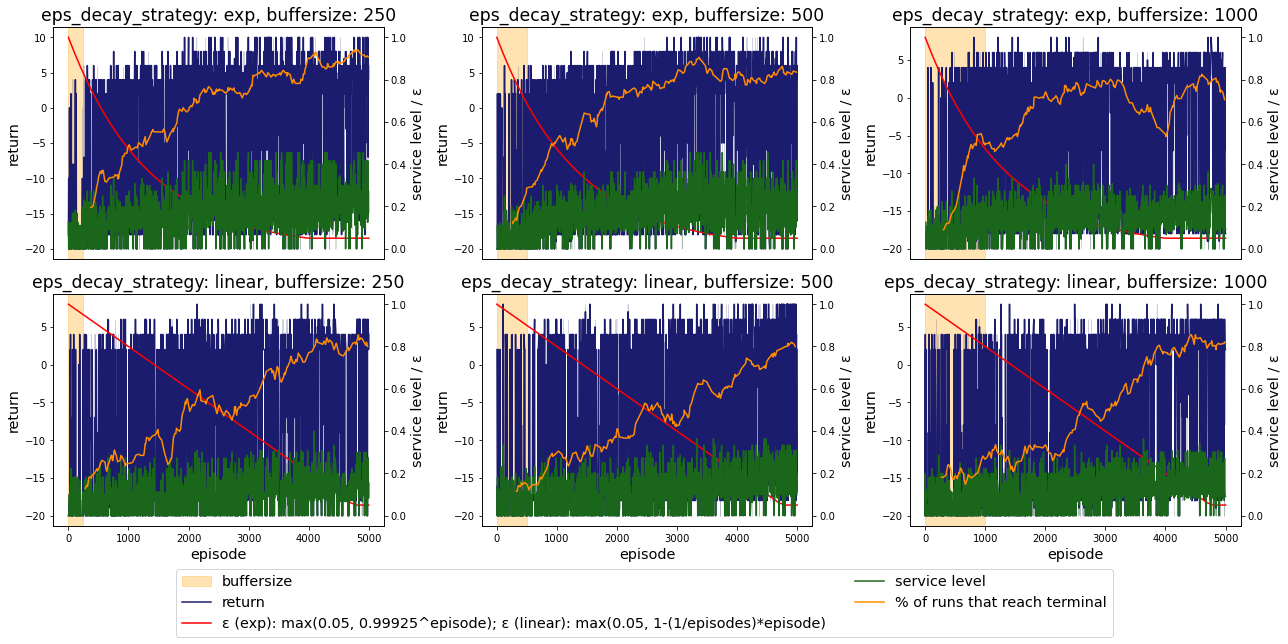

In [8]:
plt.rcParams.update({
    'axes.titlesize': 'xx-large',
    'axes.labelsize': 'x-large',
    'legend.fontsize': 'x-large',
    'legend.title_fontsize': 'large'
})

RESULTS = 'search_buffersize_eps_decay_strategy_seed_experiments_20220116-033513.csv'
COLS = ['episode', 'return', 'service_level', 'lr', 'reached_destination', 'distance', 'duration']

config = {'episodes': episodes, 
          'actions': actions,
          'tau': tau,
          'update every n steps': target_update_threshold,
          'penalty': penalty,
          'reward': reward,
          'learning rate decay': lr_decay,
          'learning rate decay steps': lr_decay_steps,
          'batchsize': batchsize,
          'q net': q_net_layers
         }

results = pd.read_csv(os.path.join(DATAPATH, 'returns', RESULTS))
results.drop(columns='seed', inplace=True, errors='ignore')
results = results.sample(frac=.1, axis='index')
experiments = list(set(results) - set(COLS))

e1 = results[experiments[0]]
e2 = results[experiments[1]]
n_e1 = e1.nunique()
n_e2 = e2.nunique()
fig, ax = plt.subplots(nrows=n_e1, ncols=n_e2, figsize=(6*n_e2,4*n_e1))
ii = 0

for i, (name, group) in enumerate(results.groupby(experiments)):
    group = group.join(group.groupby('episode')['reached_destination'].mean().rolling(100).mean(), on='episode', rsuffix='_MA')
    group['return_MA'] = group['return'].rolling(20).mean()
    group['service_level_MA'] = group['service_level'].rolling(20).mean()

    if i >= n_e2:
        ii = i // n_e2
        i -= ii * n_e2

    # annotations
    if 'buffersize' in experiments:
        buffersize_i = experiments.index('buffersize')
        ax[ii][i].axvspan(0, name[buffersize_i], color='orange', alpha=.3, label='buffersize')
    else:
        ax[ii][i].axvspan(0, buffersize, color='orange', alpha=.3, label='buffersize')
    # ax[ii][i].axvline(min_experience, color='black', label='training start')

    x_ = np.linspace(1,episodes)
    ax_ = ax[ii][i].twinx()
    ax2 = ax[ii][i].twinx()
    if 'eps_decay_strategy' in experiments:
        epsdecaystrategy_i = experiments.index('eps_decay_strategy')
        eps_decay_strategy = name[epsdecaystrategy_i]
    if eps_decay_strategy == 'exp':
        if 'eps_decay' in experiments:
            epsdecay_i = experiments.index('eps_decay')
            sns.lineplot(x=x_, y=np.maximum(name[epsdecay_i]**x_, eps_min), color='red', ax=ax2, label=f'ɛ: max({eps_min}, {name}^episode)', legend=False)
        else:
            sns.lineplot(x=x_, y=np.maximum(eps_decay**x_, eps_min), color='red', ax=ax2, label=f'ɛ: max({eps_min}, {eps_decay}^episode)', legend=False)
    if eps_decay_strategy == 'linear':
        sns.lineplot(x=x_, y=np.maximum(1-(1/episodes)*x_, eps_min), color='red', ax=ax2, label=f'ɛ: max({eps_min}, 1-(1/episodes)*episode)', legend=False)
    if eps_decay_strategy == 'none':
        config.pop('eps_decay', None)
        config.pop('eps_min', None)
        config['eps'] = eps
    # hide this axis
    ax_.set_axis_off()

    sns.lineplot(data=group, x='episode', y='return', color=sns.desaturate('darkblue', .6), label='return', ax=ax[ii][i], legend=False)
#         sns.lineplot(data=group, x='episode', y='return_MA', alpha=1, color='blue', label='MA return', ax=ax[i], legend=False)
    sns.lineplot(data=group, x='episode', y='service_level', color=sns.desaturate('green', .6), label='service level', ax=ax2, legend=False)
#         sns.lineplot(data=group, x='episode', y='service_level_MA', alpha=1, color='green', label='MA service level', ax=ax2, legend=False)
    sns.lineplot(data=group[group.duplicated(subset=['episode'])], x='episode', y='reached_destination_MA', color='darkorange', label='% of runs that reach terminal', ax=ax2, legend=False)

    ax2.set_ylabel('service level / ɛ')

    exp = {k: v for k, v in zip(experiments, name)}
    ax[ii][i].set_title(', '.join(f'{k}: {v}' for k, v in exp.items()))

    if ii < n_e1-1:
        # upper rows
        ax[ii][i].set_xticks([])
        ax[ii][i].set_xlabel(None)

handles, labels = [(a + b) for a, b in zip(ax[ii][i].get_legend_handles_labels(), ax2.get_legend_handles_labels())]
labels[2] = f'ɛ (exp): max(0.05, {eps_decay}^episode); ɛ (linear): max(0.05, 1-(1/episodes)*episode)'
lgd = fig.legend(handles, labels, loc="lower center", ncol=len(labels)//2, bbox_to_anchor=(0.5,-0.125))

fig.patch.set_facecolor('white')
fig.tight_layout()
# fig.suptitle('Experiment with Penalty = 15, soft update with tau=0.001 at every step', fontsize=15)
# fig.subplots_adjust(top=0.95)
# lgd = fig.legend(handles, labels, bbox_to_anchor=(1.04,0.35), loc="center left")

config_handles = []
for k,v in config.items():
    config_handles.append(mpatches.Patch(color='none', label=f'{k} = {v}'))
# lgd2 = fig.legend(handles=config_handles, bbox_to_anchor=(1.04,0.65), loc="center left", title="Configuration")

plt.savefig(os.path.join(DATAPATH, RESULTS.replace('.csv', '.png')), bbox_extra_artists=(lgd,), bbox_inches='tight')
plt.show()

# Single (averaged) agent evaluation

In [3]:
RESULTS = 'average_10_experiments_20220113-145546.csv'
ROLLING = 100

config = {'episodes': episodes, 
          'actions': actions,
          'tau': tau,
          'update every n steps': target_update_threshold,
          'penalty': penalty,
          'reward': reward,
          'batchsize': batchsize,
          'q net': q_net_layers
         }

results = pd.read_csv(os.path.join(DATAPATH, 'returns', RESULTS))

# %%
# results = results[results['penalty'] == 15]
results['return_MA'] = results['return'].rolling(ROLLING).mean()
results['service_level_MA'] = results['service_level'].rolling(ROLLING).mean()
results['reached_destination_MA'] = results['reached_destination'].rolling(ROLLING).mean()

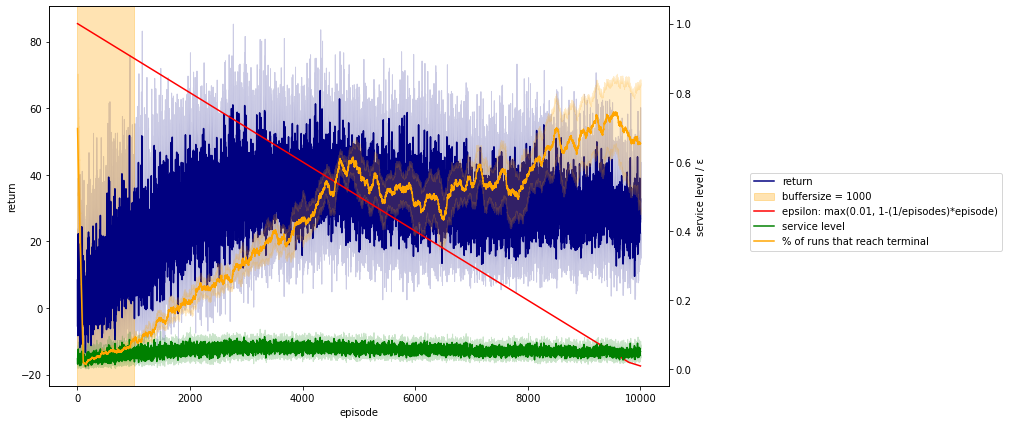

In [6]:
fig, ax = plt.subplots(figsize=(10,6))
# annotations
plt.axvspan(0, buffersize, color='orange', alpha=.3, label=f'buffersize = {buffersize}')
# plt.axvline(min_experience, color='black', label=f'training start after {episodes} episodes')
x_ = np.linspace(1,episodes)
ax_ = plt.twinx(ax)
ax2 = ax.twinx()
if eps_decay_strategy == 'exp':
    sns.lineplot(x=x_, y=np.maximum(0.9994**x_, eps_min), color='red', ax=ax2, label=f'epsilon (1->{eps_min})', legend=False)
if eps_decay_strategy == 'linear':
    sns.lineplot(x=x_, y=np.maximum(1-(1/episodes)*x_, eps_min), color='red', ax=ax2, label=f'epsilon: max({eps_min}, 1-(1/episodes)*episode)', legend=False)
ax_.set_axis_off() # hide this axis

if len(results) == episodes:
    # single agent
    sns.lineplot(data=results, x='episode', y='return', alpha=.2, color='darkblue', label='return', ax=ax, legend=False)
    sns.lineplot(data=results, x='episode', y='return_MA', alpha=1, color='navy', label='MA return', ax=ax, legend=False)
    sns.lineplot(data=results, x='episode', y='service_level', alpha=.2, color='green', label='service level', ax=ax2, legend=False)
    sns.lineplot(data=results, x='episode', y='service_level_MA', alpha=1, color='green', label='MA service level', ax=ax2, legend=False)
else:
    # multiple agents were evaluated at the same time for averaging
    sns.lineplot(data=results, x='episode', y='return', alpha=1, color='navy', label='return', ax=ax, legend=False)
    sns.lineplot(data=results, x='episode', y='service_level', alpha=1, color='green', label='service level', ax=ax2, legend=False)
sns.lineplot(data=results, x='episode', y='reached_destination_MA', color='orange', label='% of runs that reach terminal', ax=ax2, legend=False)

# plt.title('Experiment with tanh activation function in hidden layers')
ax2.set_ylabel('service level / ɛ')

handles, labels = [(a + b) for a, b in zip(ax.get_legend_handles_labels(), ax2.get_legend_handles_labels())]
fig.patch.set_facecolor('white')
fig.tight_layout()
# fig.suptitle('Experiment with Penalty = 15, soft update with tau=0.001 at every step', fontsize=15)
# fig.subplots_adjust(top=0.95)
lgd = fig.legend(handles, labels, bbox_to_anchor=(1.04,0.5), loc="center left")
config_handles = []
for k,v in config.items():
    config_handles.append(mpatches.Patch(color='none', label=f'{k} = {v}'))
# lgd2 = fig.legend(handles=config_handles, bbox_to_anchor=(1.04,0.8), loc="center left", title="Configuration")

plt.savefig(os.path.join(DATAPATH, RESULTS.replace('.csv', '.png')), bbox_extra_artists=(lgd,), bbox_inches='tight')
plt.show()

## find best of runs

In [45]:
runs = [
    '5000_episodes_buffersize=1000_eps_decay_strategy=exp_returns_20220116-033023.csv',
    '5000_episodes_buffersize=1000_eps_decay_strategy=exp_returns_20220116-033112.csv',
    '5000_episodes_buffersize=1000_eps_decay_strategy=exp_returns_20220116-033149.csv',
    '5000_episodes_buffersize=1000_eps_decay_strategy=exp_returns_20220116-033510.csv',
    '5000_episodes_buffersize=1000_eps_decay_strategy=linear_returns_20220116-032802.csv',
    '5000_episodes_buffersize=1000_eps_decay_strategy=linear_returns_20220116-032938.csv',
    '5000_episodes_buffersize=1000_eps_decay_strategy=linear_returns_20220116-033115.csv',
    '5000_episodes_buffersize=1000_eps_decay_strategy=linear_returns_20220116-033244.csv',
    '5000_episodes_buffersize=250_eps_decay_strategy=exp_returns_20220116-032930.csv',
    '5000_episodes_buffersize=250_eps_decay_strategy=exp_returns_20220116-033051.csv',
    '5000_episodes_buffersize=250_eps_decay_strategy=exp_returns_20220116-033154.csv',
    '5000_episodes_buffersize=250_eps_decay_strategy=exp_returns_20220116-033348.csv',
    '5000_episodes_buffersize=250_eps_decay_strategy=linear_returns_20220116-032645.csv',
    '5000_episodes_buffersize=250_eps_decay_strategy=linear_returns_20220116-032740.csv',
    '5000_episodes_buffersize=250_eps_decay_strategy=linear_returns_20220116-032834.csv',
    '5000_episodes_buffersize=250_eps_decay_strategy=linear_returns_20220116-033034.csv',
    '5000_episodes_buffersize=500_eps_decay_strategy=exp_returns_20220116-033026.csv',
    '5000_episodes_buffersize=500_eps_decay_strategy=exp_returns_20220116-033030.csv',
    '5000_episodes_buffersize=500_eps_decay_strategy=exp_returns_20220116-033308.csv',
    '5000_episodes_buffersize=500_eps_decay_strategy=exp_returns_20220116-033411.csv',
    '5000_episodes_buffersize=500_eps_decay_strategy=linear_returns_20220116-032832.csv',
    '5000_episodes_buffersize=500_eps_decay_strategy=linear_returns_20220116-033113.csv',
    '5000_episodes_buffersize=500_eps_decay_strategy=linear_returns_20220116-033121.csv',
    '5000_episodes_buffersize=500_eps_decay_strategy=linear_returns_20220116-033231.csv',
]

In [54]:
LAST_N = 100

evaluate_results = []

for r in runs:
    run_results = pd.read_csv(os.path.join(DATAPATH, 'returns', r))
    e_cols = list(set(run_results) - set(['service_level', 'episode', 'reached_destination', 'lr', 'return']))
    evaluate_results.append(
        {'run': r,
         'mean_service': run_results["service_level"].mean(), 
         'last_mean_service': run_results["service_level"][-LAST_N:].mean(), 
         'reached_destination': run_results["reached_destination"].mean(), 
         'last_reached_destination': run_results["reached_destination"][-LAST_N:].mean(),
         'experiments': str(run_results.loc[0,e_cols].to_dict())}
    )
    # print(f'Run {r}: \n\tLast runs service level: {run_results["service_level"][-10:].mean()} \n\tLast runs of reaching destination: {run_results["reached_destination"][-10:].mean()}\n\tMean service level: {run_results["service_level"].mean()} \n\tMean of reaching destination: {run_results["reached_destination"].mean()}\n')

In [55]:
evaluate_results = pd.DataFrame.from_records(evaluate_results)
evaluate_results.groupby('experiments').mean()

,mean_service,last_mean_service,reached_destination,last_reached_destination
experiments,,,,
"{'eps_decay_strategy': 'exp', 'buffersize': 1000}",0.145715,0.154737,0.61980,0.6325
"{'eps_decay_strategy': 'exp', 'buffersize': 250}",0.167951,0.233197,0.67995,0.8850
"{'eps_decay_strategy': 'exp', 'buffersize': 500}",0.170918,0.206716,0.67635,0.8175
"{'eps_decay_strategy': 'linear', 'buffersize': 1000}",0.123027,0.163416,0.49225,0.8250
"{'eps_decay_strategy': 'linear', 'buffersize': 250}",0.101599,0.146035,0.52540,0.8150
"{'eps_decay_strategy': 'linear', 'buffersize': 500}",0.122078,0.189440,0.47860,0.8525


In [15]:
# filter out agents that do not reach the destination reliably
evaluate_results_filtered = evaluate_results[evaluate_results['last_reached_destination'] >= 0.8]
# filter out agents that are not stable
# evaluate_results_filtered = evaluate_results_filtered[evaluate_results_filtered['last_mean_service']>=evaluate_results_filtered['mean_service']]
evaluate_results_filtered

,run,mean_service,last_mean_service,reached_destination,last_reached_destination,experiments
1,10000_episodes_returns_20220113-133605.csv,0.050641,0.024757,0.4827,1.0,{}
2,10000_episodes_returns_20220113-140936.csv,0.052739,0.042136,0.4278,1.0,{}
3,10000_episodes_returns_20220113-141230.csv,0.053250,0.043565,0.4650,1.0,{}
4,10000_episodes_returns_20220113-141709.csv,0.056329,0.052059,0.4266,1.0,{}


In [136]:
evaluate_results_filtered.loc[12, 'run']

'5000_episodes_doubleQ=False_tau=0.001_returns_20220110-114228.csv'

# Benchmark best run

In [10]:
plt.rcParams.update({
    'axes.titlesize': 'xx-large',
    'axes.labelsize': 'x-large',
    'legend.fontsize': 'large',
    'legend.title_fontsize': 'large'
})

BENCHMARK_PATH = 'benchmarks'
# BENCHMARK = '100_episodes_benchmark_20220105-115141.csv' # BACKUP: currently used for results
BENCHMARK = '100_episodes_benchmark_20220115-145647.csv'
ROLLING = 1

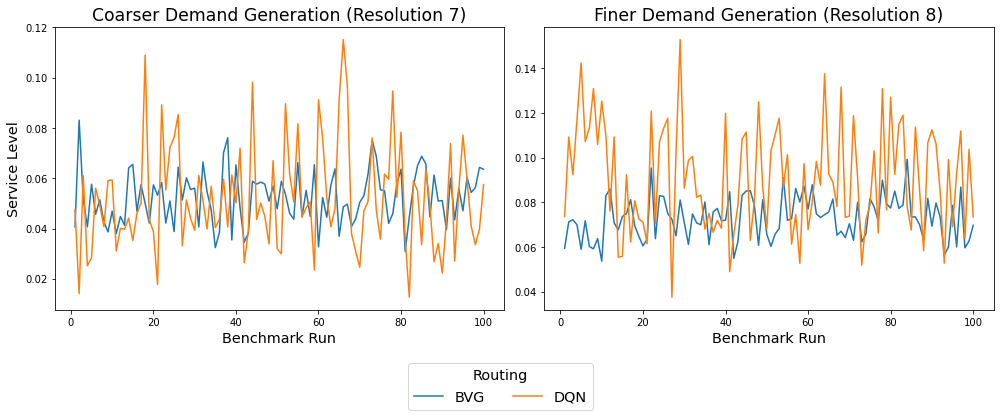

In [14]:
benchmark_results = pd.read_csv(os.path.join(DATAPATH, BENCHMARK_PATH, BENCHMARK))
# noinspection JupyterPackage
# benchmark_results.loc[benchmark_results['type']=='DQN', 'service_level_MA'] = benchmark_results.loc[benchmark_results['type']=='DQN', 'service_level'].rolling(ROLLING).mean()
# benchmark_results.loc[benchmark_results['type']=='BVG', 'service_level_MA'] = benchmark_results.loc[benchmark_results['type']=='BVG', 'service_level'].rolling(ROLLING).mean()

fig, ax = plt.subplots(1,2, figsize=(14,5))

sns.lineplot(ax=ax[0], data=benchmark_results[benchmark_results['spatial_res']==7], x='run', y='service_level', hue='type')
ax[0].legend().remove()
ax[0].set_title('Coarser Demand Generation (Resolution 7)')
sns.lineplot(ax=ax[1], data=benchmark_results[benchmark_results['spatial_res']==8], x='run', y='service_level', hue='type', legend=False)
ax[1].set_title('Finer Demand Generation (Resolution 8)')


for a in ax:
    a.set_xlabel('Benchmark Run')
ax[0].set_ylabel('Service Level')
ax[1].set_ylabel(None)

handles, labels = ax[0].get_legend_handles_labels()
fig.patch.set_facecolor('white')
fig.tight_layout()
lgd = fig.legend(handles, labels, bbox_to_anchor=(0.5,0), loc="upper center", ncol=2, title='Routing', fontsize='x-large', title_fontsize='x-large')

plt.savefig(os.path.join(DATAPATH, BENCHMARK_PATH, BENCHMARK.replace('.csv', '.png')), bbox_extra_artists=(lgd,), bbox_inches='tight')
plt.show()

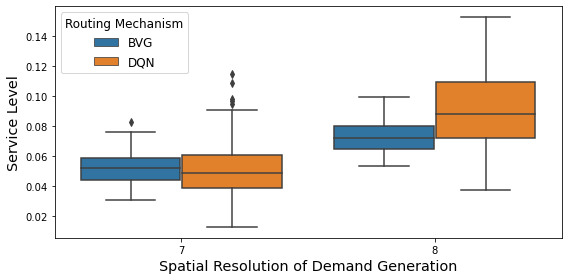

In [12]:
fig, ax = plt.subplots(1,1,figsize=(8,4))
sns.boxplot(ax=ax, data=benchmark_results, x='spatial_res', y='service_level', hue='type')
ax.set_xlabel('Spatial Resolution of Demand Generation')
ax.set_ylabel('Service Level')
ax.legend(title='Routing Mechanism')

fig.patch.set_facecolor('white')
fig.tight_layout()

plt.savefig(os.path.join(DATAPATH, BENCHMARK_PATH, BENCHMARK.replace('.csv', '_boxplot.png')), bbox_inches='tight')
plt.show()

In [11]:
benchmark_stats_full = benchmark_results.groupby(['type', 'spatial_res']).describe().drop(columns='run').drop(columns=['count', 'std'], level=1)
benchmark_stats_min = benchmark_stats_full.loc[:,(['service_level', 'distance', 'duration'], 'mean')]
benchmark_stats_min.columns = benchmark_stats_min.columns.droplevel(level=1)

In [12]:
# inline table with means only
benchmark_stats_min.loc[:,'distance'] = benchmark_stats_min.loc[:,'distance'] / 1000
benchmark_stats_min.loc[:,'service_level'] = benchmark_stats_min.loc[:,'service_level'].map('{:.2%}'.format)
benchmark_stats_min.loc[('DQN',7),'reaching destination'] = '{:.0%}'.format(benchmark_results.loc[(benchmark_results['type']=='DQN') & (benchmark_results['spatial_res']==7), 'reached_destination'].mean())
benchmark_stats_min.loc[('DQN',8),'reaching destination'] = '{:.0%}'.format(benchmark_results.loc[(benchmark_results['type']=='DQN') & (benchmark_results['spatial_res']==8), 'reached_destination'].mean())
benchmark_stats_min.loc['BVG','reaching destination'] = '100%'
benchmark_stats_min

/Users/janik/miniconda3/envs/urban-mobility-simulation/lib/python3.9/site-packages/pandas/core/indexing.py:1951: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self.obj[selected_item_labels] = value
/Users/janik/miniconda3/envs/urban-mobility-simulation/lib/python3.9/site-packages/pandas/core/indexing.py:1773: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_single_column(ilocs[0], value, pi)
/Users/janik/miniconda3/envs/urban-mobility-simulation/lib/python3.9/site-packages/pandas/core/indexing.py

service_level   distance   duration reaching destination
type spatial_res                                                         
BVG  7                   5.24%  12.358056  48.000000                 100%
     8                   7.29%  12.358056  48.000000                 100%
DQN  7                   5.19%  23.682490  47.364981                  48%
     8                   9.09%  21.133023  42.266046                  95%

In [13]:
COLUMN_FORMAT = 'llrrrr'

latex = benchmark_stats_min.to_latex(column_format=COLUMN_FORMAT, float_format="{:,.2f}".format, caption='Mean service, distance, and duration of 100 benchmark runs', label='tab:benchmarks', position='t')

# rename things
latex = latex.replace('type', 'Routing')
latex = latex.replace('service\_level', 'Service Level')
latex = latex.replace('spatial\_res', 'Demand$^{1}$')
latex = latex.replace('reaching destination', 'Terminal$^{2}$')
latex = latex.replace('distance', 'Distance (km)')
latex = latex.replace('duration', 'Duration (min)')
latex = latex.replace('\\centering', '\\setlength{\\tabcolsep}{4pt} \n\\centering')
notes = """
\\bottomrule
\multicolumn{6}{l}{\small $^{1}$Granularity of demand generation process, in h3 cell resolution.} \\\\ 
\multicolumn{6}{l}{\small $^{2}$Percentage of runs that arrive at the terminal destination in time.} \\\\
\\bottomrule"""
latex = latex.replace('\\bottomrule', notes)

with open(os.path.join(DATAPATH, 'figures', 'benchmark_small.tex'), 'w') as f:
    f.write(latex)
print(latex)

\begin{table}[t]
\setlength{\tabcolsep}{4pt} 
\centering
\caption{Mean service, Distance (km), and Duration (min) of 100 benchmark runs}
\label{tab:benchmarks}
\begin{tabular}{llrrrr}
\toprule
    &   & Service Level &  Distance (km) &  Duration (min) & Terminal$^{2}$ \\
Routing & Demand$^{1}$ &               &           &           &                      \\
\midrule
BVG & 7 &         5.24\% &     12.36 &     48.00 &                 100\% \\
    & 8 &         7.29\% &     12.36 &     48.00 &                 100\% \\
DQN & 7 &         5.19\% &     23.68 &     47.36 &                  48\% \\
    & 8 &         9.09\% &     21.13 &     42.27 &                  95\% \\

\bottomrule
\multicolumn{6}{l}{\small $^{1}$Granularity of demand generation process, in h3 cell resolution.} \\ 
\multicolumn{6}{l}{\small $^{2}$Percentage of runs that arrive at the terminal destination in time.} \\
\bottomrule
\end{tabular}
\end{table}



In [14]:
# benchmark_stats_full = benchmark_results.groupby(['type', 'spatial_res']).describe().drop(columns='episode').drop(columns=['count', 'std'], level=1)
benchmark_stats_full.loc[:,'service_level'] = benchmark_stats_full.loc[:,('service_level',)].applymap('{:.2%}'.format).values
benchmark_stats_full.loc[:,'distance'] = (benchmark_stats_full.loc[:,'distance'] / 1000).values
benchmark_stats_full.loc[('DQN',7),'destination'] = '{:.0%}'.format(benchmark_results.loc[(benchmark_results['type']=='DQN') & (benchmark_results['spatial_res']==7), 'reached_destination'].mean())
benchmark_stats_full.loc[('DQN',8),'destination'] = '{:.0%}'.format(benchmark_results.loc[(benchmark_results['type']=='DQN') & (benchmark_results['spatial_res']==8), 'reached_destination'].mean())
benchmark_stats_full.loc['BVG','destination'] = '100%'
benchmark_stats_full = benchmark_stats_full.T
benchmark_stats_full

type                      BVG                   DQN           
spatial_res                 7          8          7          8
service_level mean      5.24%      7.29%      5.19%      9.09%
              min       3.09%      5.37%      1.27%      3.76%
              25%       4.46%      6.51%      3.88%      7.20%
              50%       5.19%      7.24%      4.88%      8.84%
              75%       5.88%      8.01%      6.11%     10.95%
              max       8.31%      9.93%     11.52%     15.29%
distance      mean  12.358056  12.358056   23.68249  21.133023
              min   12.358056  12.358056  14.294454  14.202712
              25%   12.358056  12.358056  19.600691  17.660683
              50%   12.358056  12.358056  24.707503  20.302881
              75%   12.358056  12.358056  27.846915  23.939371
              max   12.358056  12.358056   34.27736  32.690012
duration      mean       48.0       48.0  47.364981  42.266046
              min        48.0       48.0  28.588908  28.405424
              25%        48.0       48.0  39.201381  35.321366
              50%        48.0       48.0  49.415005  40.605762
              75%        48.0       48.0   55.69383  47.878741
              max        48.0       48.0  68.554721  65.380024
destination              100%       100%        48%        95%

In [18]:
# check what quantile of DQN stays below or par BVG duration
from scipy import stats
print('Quantile of durations that stay under planned route duration, at res 8')
print(stats.percentileofscore(benchmark_results.loc[(benchmark_results['type']=='DQN')&(benchmark_results['spatial_res']==8),'duration'], 48, kind='weak'))

print('Score at that (above quantile), at res 8')
print(stats.scoreatpercentile(benchmark_results.loc[(benchmark_results['type']=='DQN')&(benchmark_results['spatial_res']==8),'duration'], stats.percentileofscore(benchmark_results.loc[(benchmark_results['type']=='DQN')&(benchmark_results['spatial_res']==8),'duration'], 48, kind='weak')))

print('Quantile of runs that perform better than mean planned route performance, at res 8')
print((100-stats.percentileofscore(benchmark_results.loc[(benchmark_results['type']=='DQN')&(benchmark_results['spatial_res']==8),'service_level'], 0.0729, kind='weak')))

print('Score at that (above) quantile')
print(stats.scoreatpercentile(benchmark_results.loc[(benchmark_results['type']=='DQN')&(benchmark_results['spatial_res']==8),'service_level'], (100-stats.percentileofscore(benchmark_results.loc[(benchmark_results['type']=='DQN')&(benchmark_results['spatial_res']==8),'service_level'], 0.0729, kind='weak'))))

print('Quantile of runs that perform better than max planned route performance, at res 8')
print((100-stats.percentileofscore(benchmark_results.loc[(benchmark_results['type']=='DQN')&(benchmark_results['spatial_res']==8),'service_level'], 0.0993, kind='weak')))

print('Score at that (above) quantile')
print(stats.scoreatpercentile(benchmark_results.loc[(benchmark_results['type']=='DQN')&(benchmark_results['spatial_res']==8),'service_level'], (100-stats.percentileofscore(benchmark_results.loc[(benchmark_results['type']=='DQN')&(benchmark_results['spatial_res']==8),'service_level'], 0.0993, kind='weak'))))

# res 7
print('Quantile of runs that perform better than mean planned route performance, at res 8')
print((100-stats.percentileofscore(benchmark_results.loc[(benchmark_results['type']=='DQN')&(benchmark_results['spatial_res']==7),'service_level'], 0.0524, kind='weak')))

print('Score at that (above) quantile')
print(stats.scoreatpercentile(benchmark_results.loc[(benchmark_results['type']=='DQN')&(benchmark_results['spatial_res']==7),'service_level'], (stats.percentileofscore(benchmark_results.loc[(benchmark_results['type']=='DQN')&(benchmark_results['spatial_res']==7),'service_level'], 0.0524, kind='weak'))))

print('Quantile of runs that perform better than max planned route performance, at res 8')
print((100-stats.percentileofscore(benchmark_results.loc[(benchmark_results['type']=='DQN')&(benchmark_results['spatial_res']==7),'service_level'], 0.0831, kind='weak')))

print('Score at that (above) quantile')
print(stats.scoreatpercentile(benchmark_results.loc[(benchmark_results['type']=='DQN')&(benchmark_results['spatial_res']==7),'service_level'], (stats.percentileofscore(benchmark_results.loc[(benchmark_results['type']=='DQN')&(benchmark_results['spatial_res']==7),'service_level'], 0.0831, kind='weak'))))

Quantile of durations that stay under planned route duration, at res 8
72.0
Score at that (above quantile), at res 8
48.23927299898977
Quantile of runs that perform better than mean planned route performance, at res 8
73.0
Score at that (above) quantile
0.10856801007556671
Quantile of runs that perform better than max planned route performance, at res 8
39.0
Score at that (above) quantile
0.07967666199306889
Quantile of runs that perform better than mean planned route performance, at res 8
40.0
Score at that (above) quantile
0.05182451466381318
Quantile of runs that perform better than max planned route performance, at res 8
10.0
Score at that (above) quantile
0.0820627450980392


In [22]:
benchmark_results.loc[(benchmark_results['type']=='DQN')&(benchmark_results['spatial_res']==8)&(benchmark_results['duration']<=48), 'service_level'].describe()

count    72.000000
mean      0.096227
std       0.021956
min       0.049046
25%       0.077478
50%       0.099034
75%       0.112728
max       0.142405
Name: service_level, dtype: float64

In [21]:
100-stats.percentileofscore(benchmark_results.loc[(benchmark_results['type']=='DQN')&(benchmark_results['spatial_res']==8)&(benchmark_results['duration']<=48), 'service_level'], 0.0729)


81.94444444444444

In [16]:
COLUMN_FORMAT = 'lllrrrr'

# dirty hack to move column multiindex labels to dummy column
benchmark_stats_full[('0', '0')] = ''

latex = benchmark_stats_full[['0','BVG','DQN']].to_latex(column_format=COLUMN_FORMAT, float_format="{:,.2f}".format, caption='Statistics of 100 benchmark runs', label='tab:benchmarks_full', position='t')

# rename things
latex = latex.replace('type & 0', ' & Routing')
latex = latex.replace('service\_level', 'Service Level')
latex = latex.replace('spatial\_res & 0', ' & Demand$^{1}$')
latex = latex.replace('destination', 'Terminal$^{2}$')
latex = latex.replace('distance', 'Distance (km)')
latex = latex.replace('duration', 'Duration (min)')
latex = latex.replace('\\centering', '\\setlength{\\tabcolsep}{4pt} \n\\centering')
notes = """
\\bottomrule
\multicolumn{7}{l}{\small $^{1}$Granularity of demand generation process, in h3 cell resolution.} \\\\ 
\multicolumn{7}{l}{\small $^{2}$Percentage of runs that arrive at the terminal destination in time.} \\\\
\\bottomrule"""
latex = latex.replace('\\bottomrule', notes)

with open(os.path.join(DATAPATH, 'figures', 'benchmark_full.tex'), 'w') as f:
    f.write(latex)
print(latex)

\begin{table}[t]
\setlength{\tabcolsep}{4pt} 
\centering
\caption{Statistics of 100 benchmark runs}
\label{tab:benchmarks_full}
\begin{tabular}{lllrrrr}
\toprule
            &  & Routing & \multicolumn{2}{l}{BVG} & \multicolumn{2}{l}{DQN} \\
            &  & Demand$^{1}$ &      7 &      8 &       7 &       8 \\
\midrule
Service Level & mean &   &  5.24\% &  7.29\% &   5.19\% &   9.09\% \\
            & min &   &  3.09\% &  5.37\% &   1.27\% &   3.76\% \\
            & 25\% &   &  4.46\% &  6.51\% &   3.88\% &   7.20\% \\
            & 50\% &   &  5.19\% &  7.24\% &   4.88\% &   8.84\% \\
            & 75\% &   &  5.88\% &  8.01\% &   6.11\% &  10.95\% \\
            & max &   &  8.31\% &  9.93\% &  11.52\% &  15.29\% \\
Distance (km) & mean &   &  12.36 &  12.36 &   23.68 &   21.13 \\
            & min &   &  12.36 &  12.36 &   14.29 &   14.20 \\
            & 25\% &   &  12.36 &  12.36 &   19.60 &   17.66 \\
            & 50\% &   &  12.36 &  12.36 &   24.71 &   20.30 \\
            &

# Code scrapyard

In [12]:
RESULTS = [
    '5000_episodes_returns_20211216-021413.csv',
    '5000_episodes_returns_20211216-030028.csv',
    '5000_episodes_returns_20211216-030903.csv',
    '5000_episodes_returns_20211216-031023.csv',
    '5000_episodes_returns_20211216-034113.csv',
    '5000_episodes_returns_20211216-041024.csv',
    '5000_episodes_returns_20211216-041230.csv',
    '5000_episodes_returns_20211216-041816.csv',
    '5000_episodes_returns_20211216-042849.csv',
    '5000_episodes_returns_20211216-043242.csv',
    '5000_episodes_returns_20211216-044310.csv',
    '5000_episodes_returns_20211216-044529.csv',
    '5000_episodes_returns_20211216-050700.csv',
    '5000_episodes_returns_20211216-050900.csv',
    '5000_episodes_returns_20211216-050953.csv',
    '5000_episodes_returns_20211216-051702.csv',
    '5000_episodes_returns_20211216-052029.csv',
    '5000_episodes_returns_20211216-052151.csv',
    '5000_episodes_returns_20211216-052437.csv',
    '5000_episodes_returns_20211216-054150.csv'
]

re = []

for r in RESULTS:
    re.append(pd.read_csv(os.path.join(DATAPATH, r)))
    
results = pd.concat(re, axis=0, ignore_index=True)
results.to_csv(os.path.join(DATAPATH,'search_reward_experiments_20211216-000000.csv'), index=False)

<AxesSubplot:label='2cc29999-6d10-4bc8-a731-3086deb3bf5c', xlabel='episode', ylabel='reached_destination'>

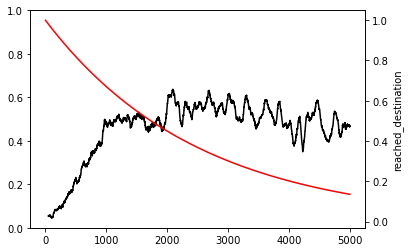

In [57]:
fig, ax = plt.subplots()
# sns.lineplot(ax=ax, data=results, x='episode', y='return', hue='reached_destination')
reached = results.groupby('episode')['reached_destination'].mean().rolling(50).mean().reset_index()
ax2 = ax.twinx()
sns.lineplot(ax=ax2, data=reached, x='episode', y='reached_destination', color='black', alpha=1)
sns.lineplot(x=x_, y=np.maximum(0.9996**x_, eps_min), color='red', ax=ax2)